In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
# Pip install method (recommended)

!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

# prevent ultralytics from tracking your activity
!yolo settings sync=False

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.3/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow==1.1.48 --quiet

from roboflow import Roboflow
rf = Roboflow(api_key="Ns8HcTHReGqbcSvgTWsw")
project = rf.workspace("manyatas-workspace").project("lc_field_detection")
version = project.version(2)
dataset = version.download("yolov8")


/content/datasets
loading Roboflow workspace...
loading Roboflow project...


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=150 imgsz=800 patience=30 plots=True

/content
New https://pypi.org/project/ultralytics/8.4.105 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/datasets/LC_Field_Detection-2/data.yaml, epochs=150, time=None, patience=30, batch=16, imgsz=800, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=Fal

/content


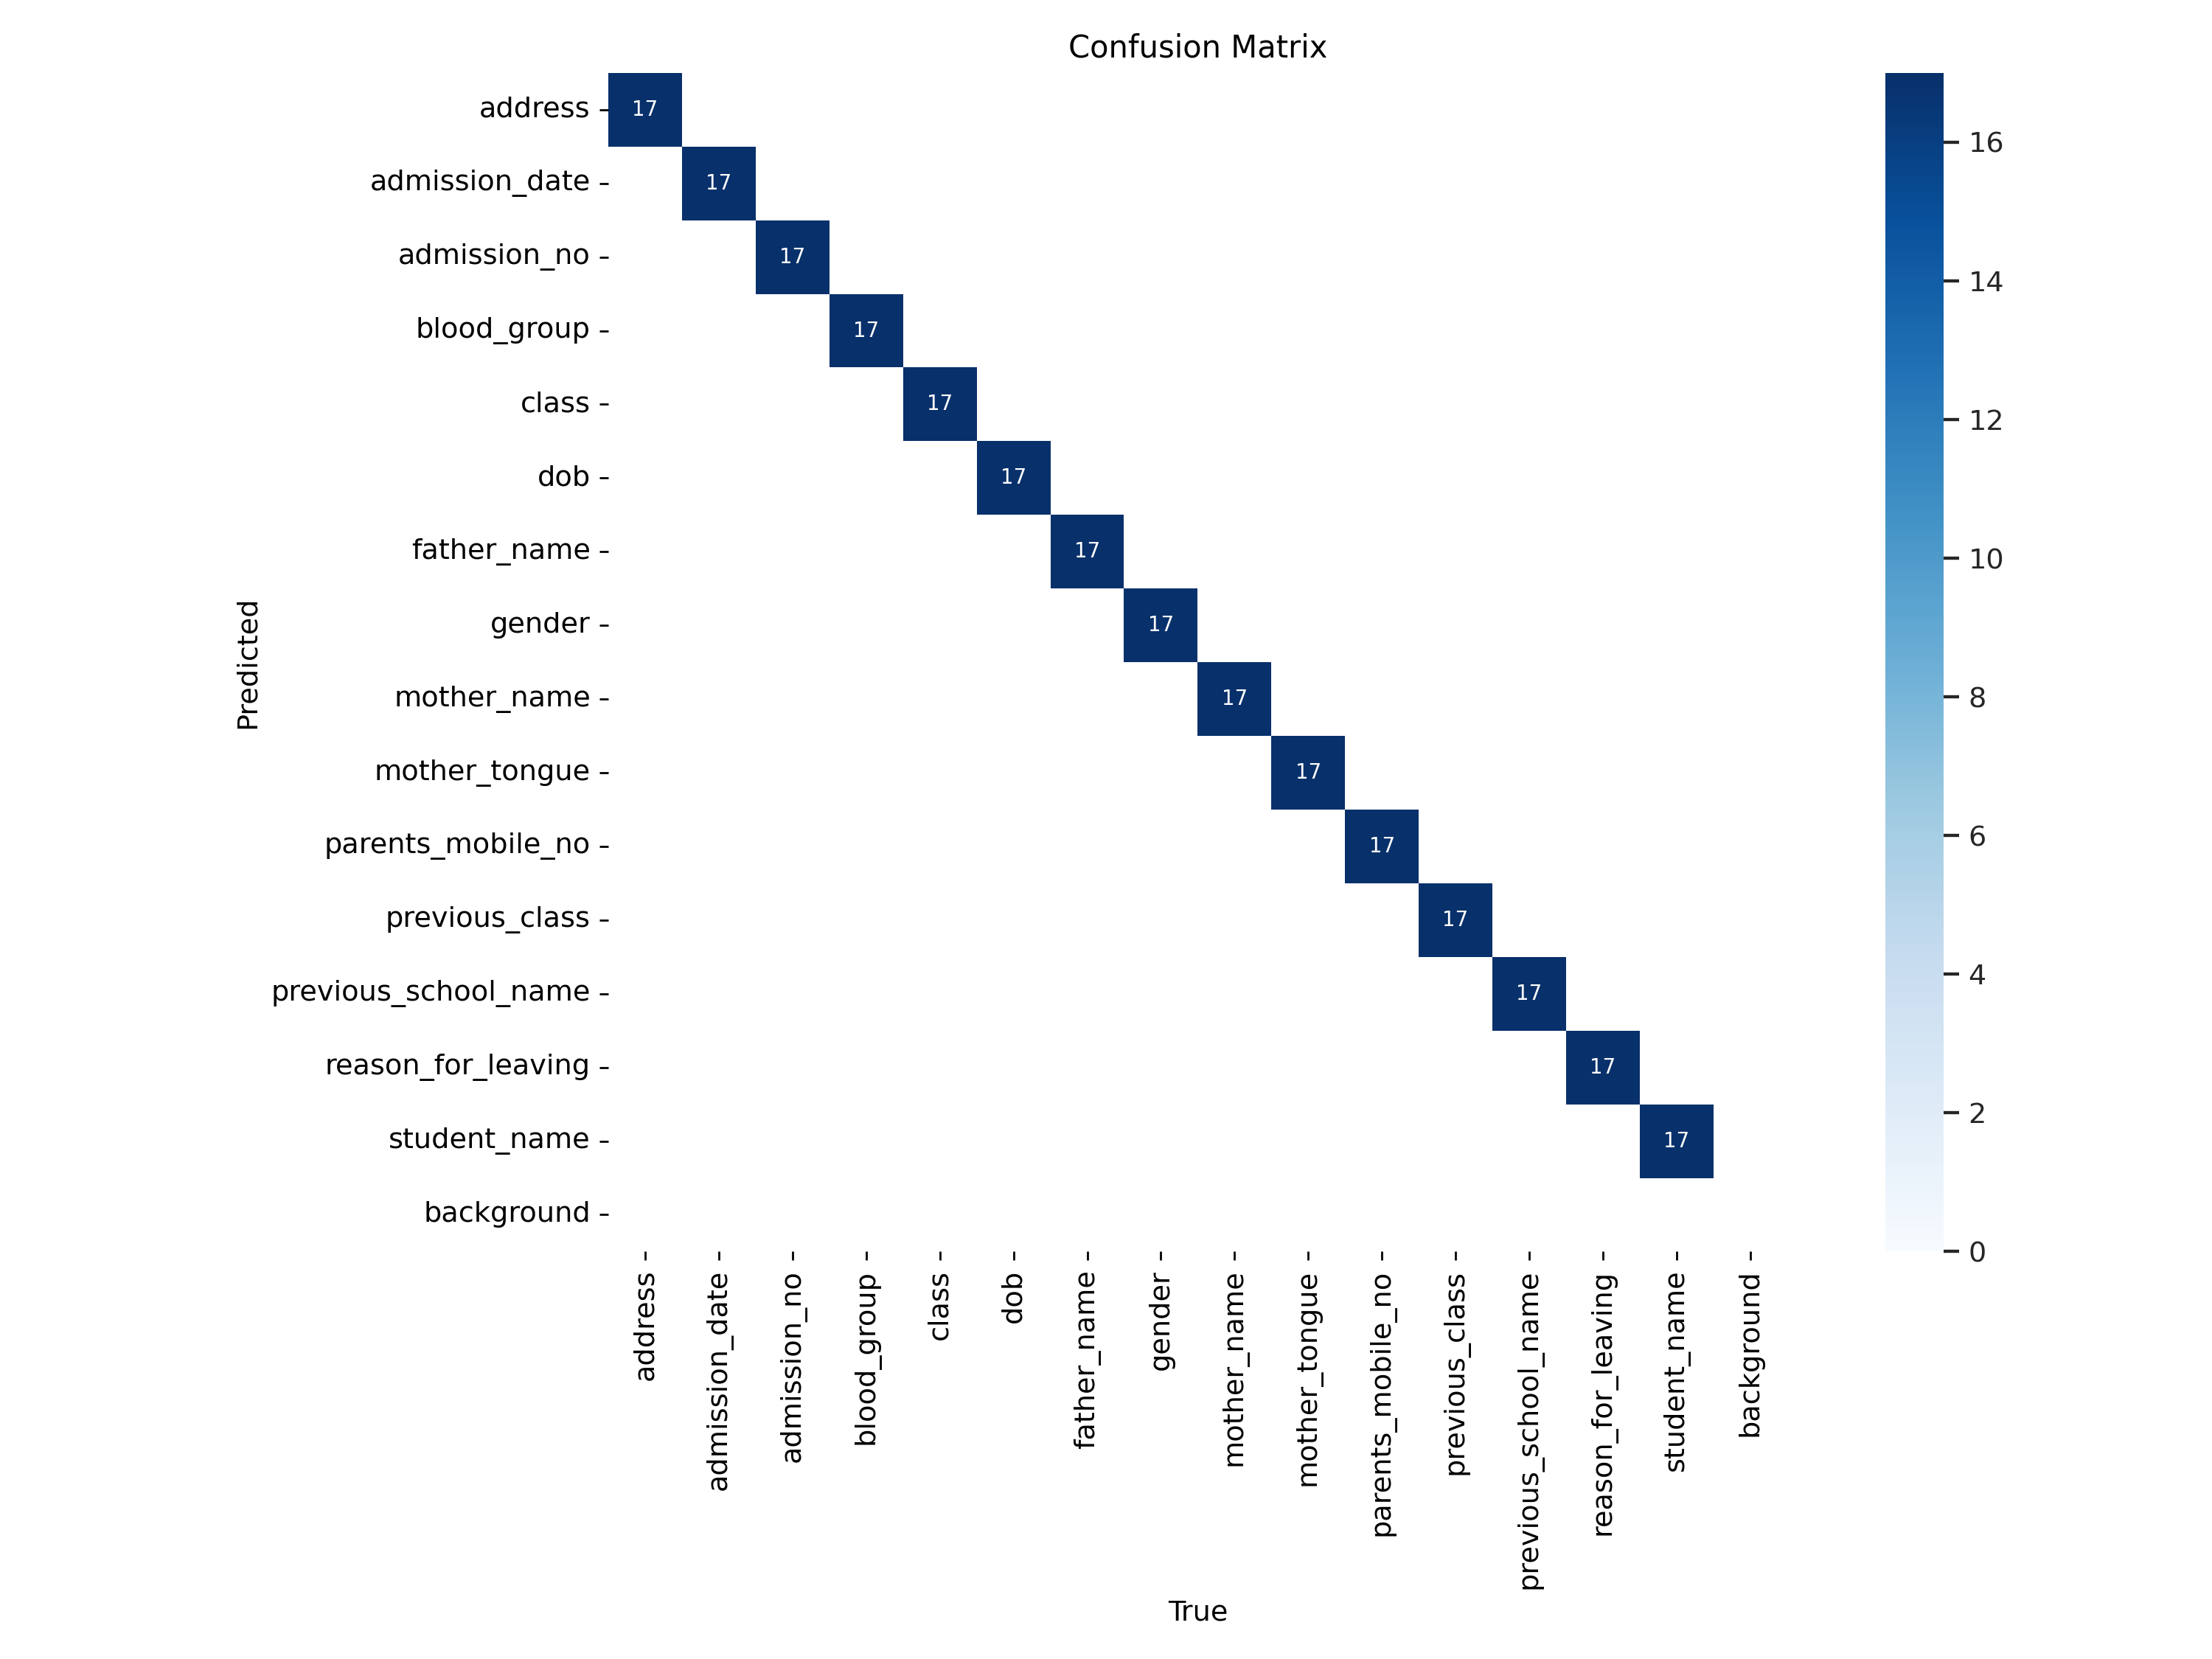

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train2/confusion_matrix.png', width=600)

/content


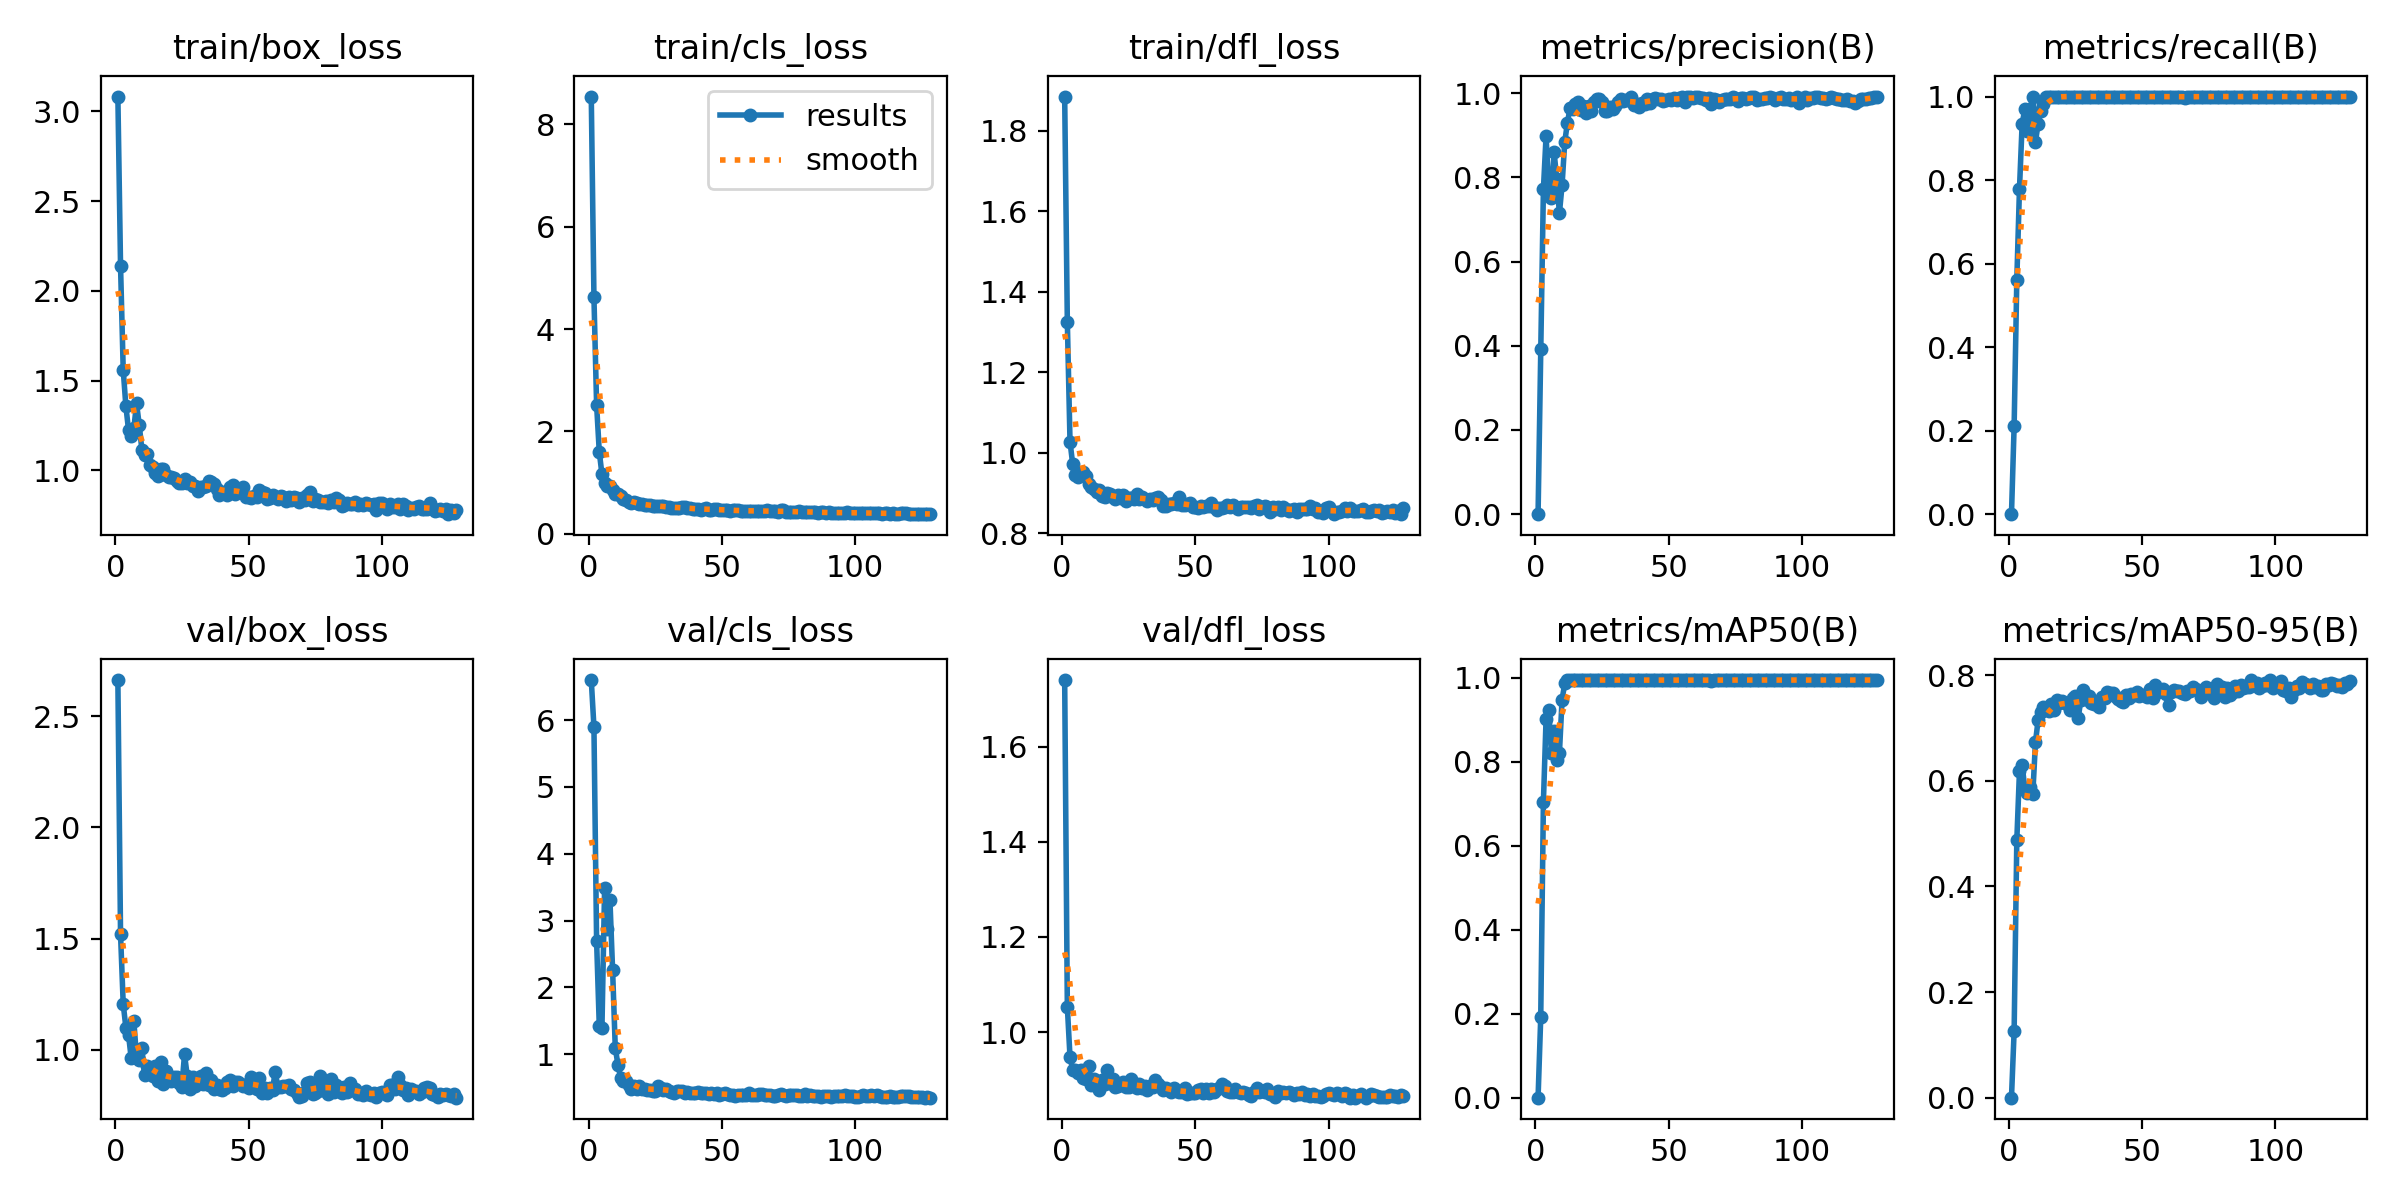

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train2/results.png', width=600)

/content


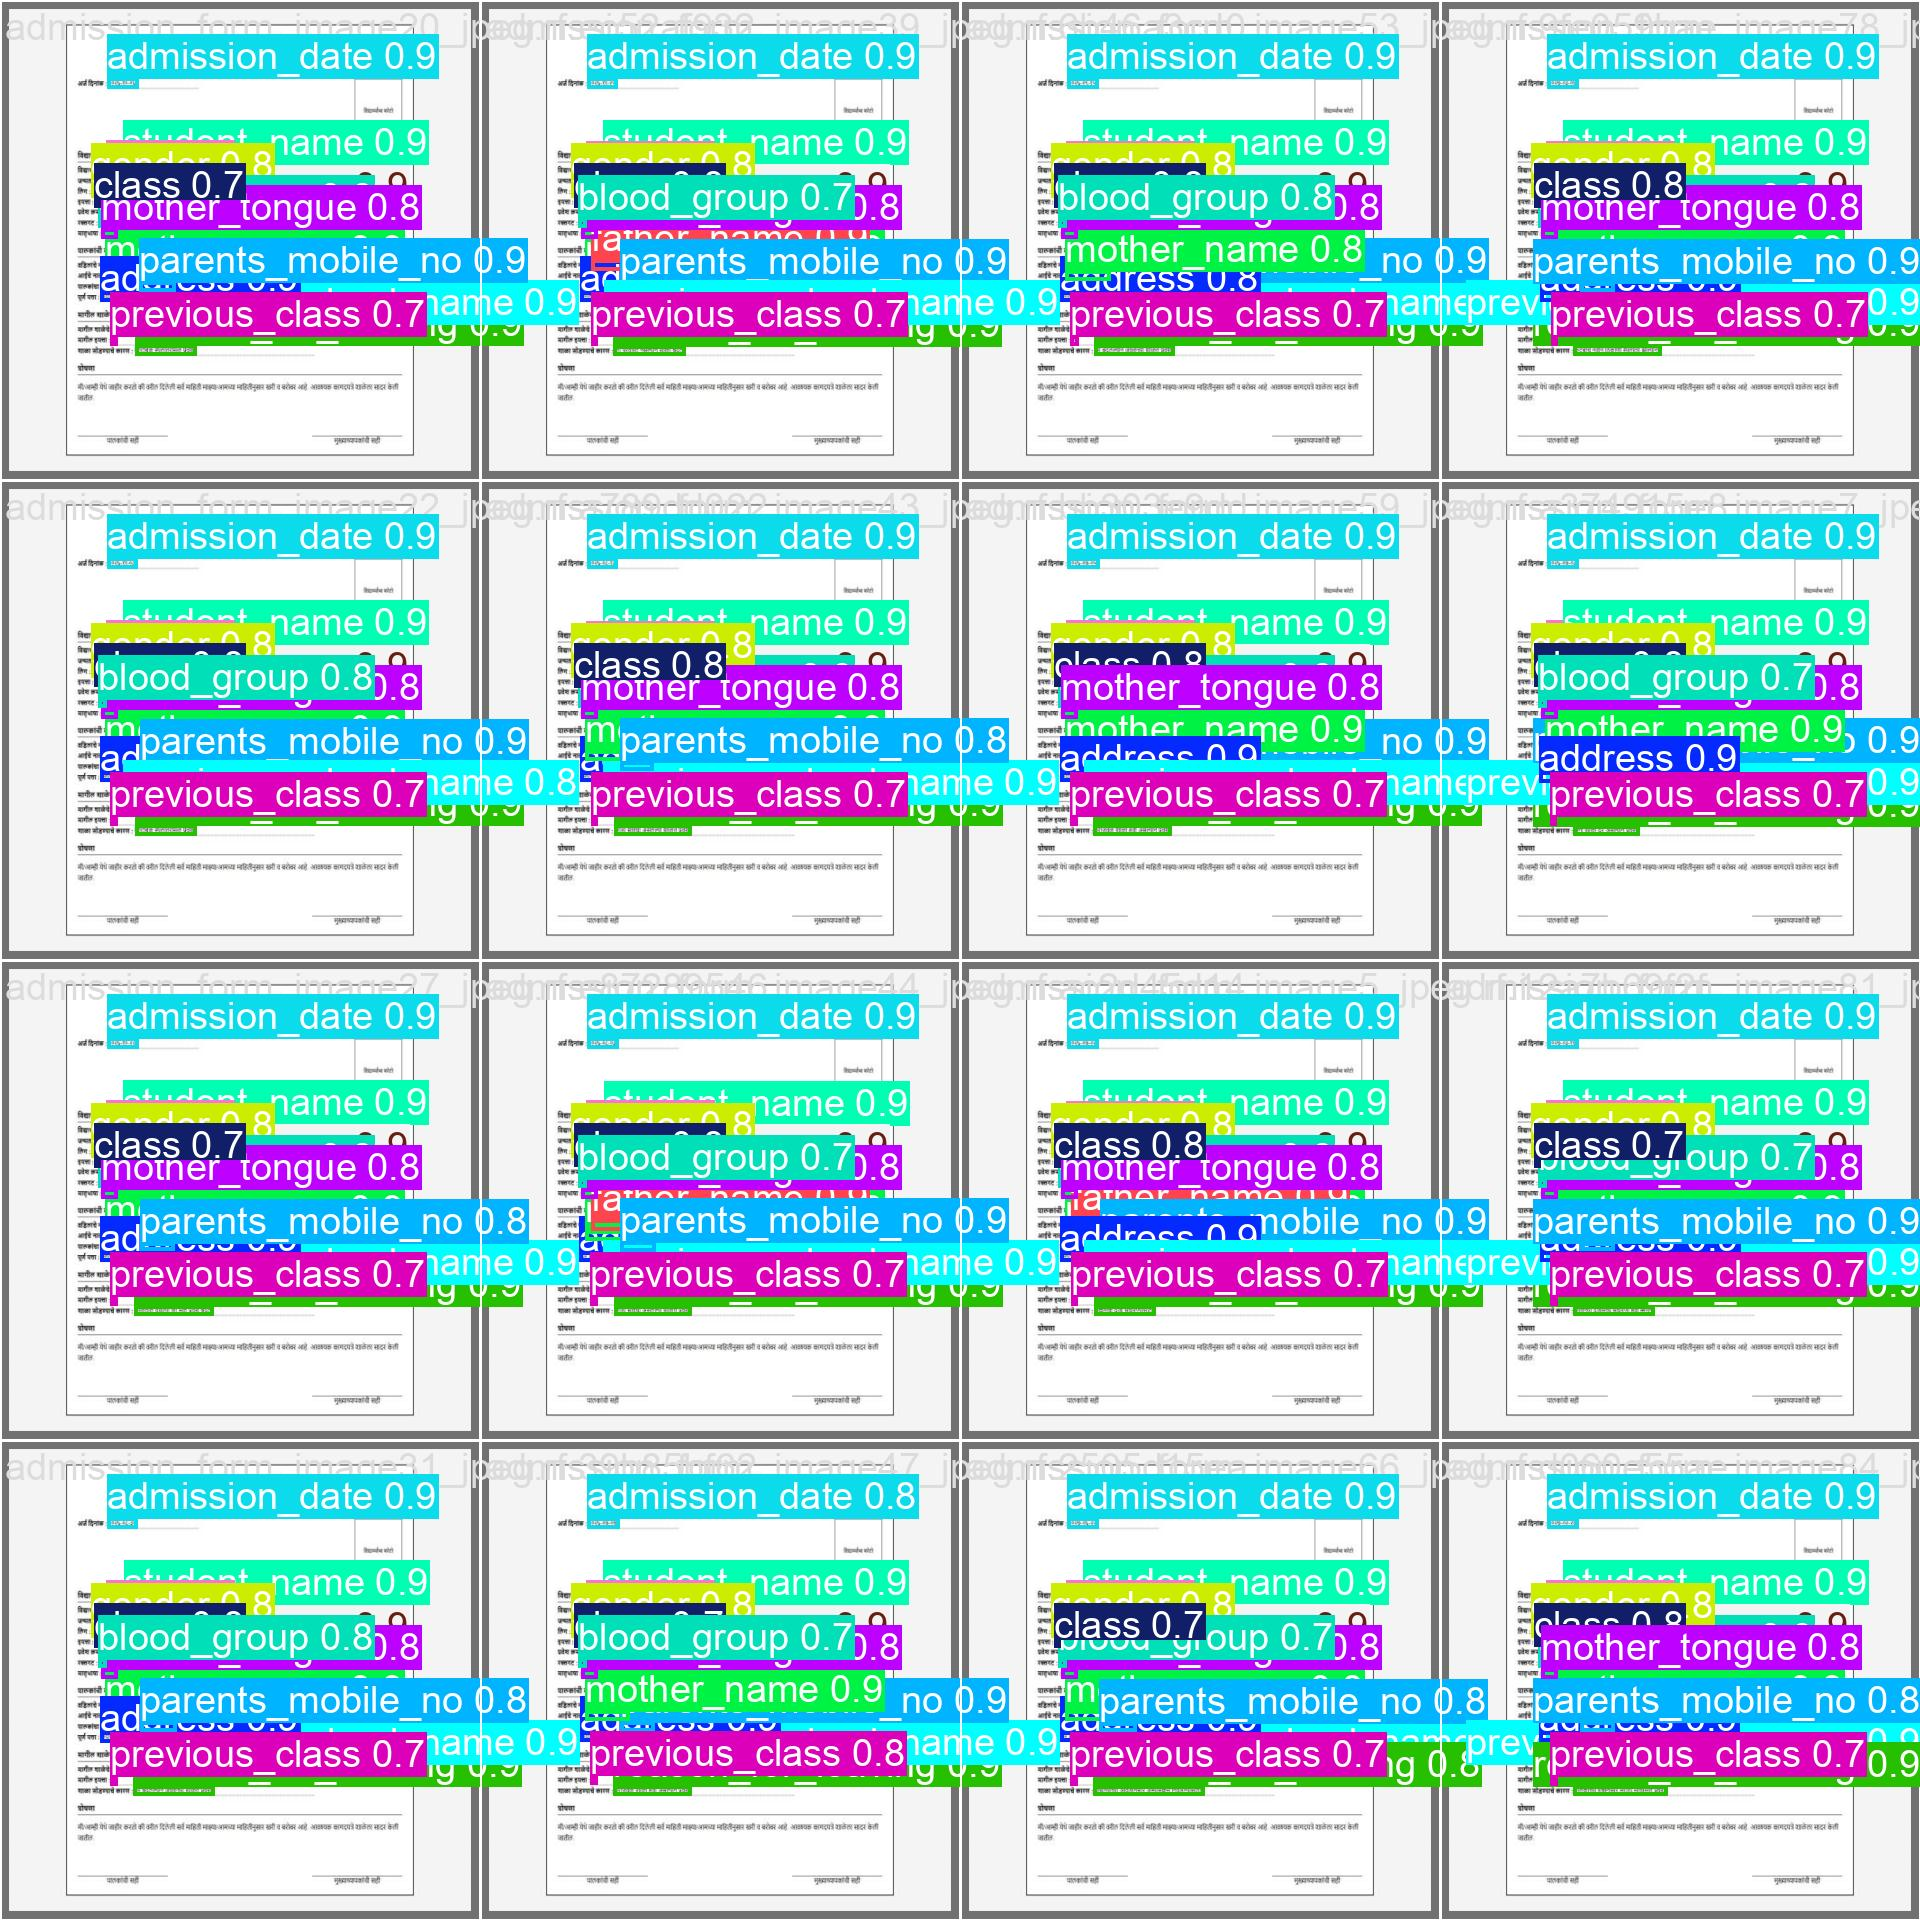

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train2/val_batch0_pred.jpg', width=600)

## Validate Custom Model

In [ ]:

%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train2/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 168 layers, 11,131,389 parameters, 0 gradients, 28.5 GFLOPs
val: Scanning /content/datasets/LC_Field_Detection-2/valid/labels.cache... 17 images, 0 backgrounds, 0 corrupt: 100% 17/17 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 2/2 [00:01<00:00,  1.09it/s]
                   all         17        255      0.991          1      0.995       0.79
               address         17         17      0.987          1      0.995      0.886
        admission_date         17         17          1          1      0.995      0.826
          admission_no         17         17      0.986          1      0.995      0.762
           blood_group         17         17      0.994          1      0.995      0.736
                 class         17         17      0.996          1      0.995      0.573
                   do

## Inference with Custom Model

In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train2/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

**NOTE:** Let's take a look at few results.

In [ ]:
import glob
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/content/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")


image 1/1 /content/admission_form_image1.jpeg: 736x800 1 address, 1 admission_date, 1 blood_group, 1 class, 1 dob, 1 father_name, 1 gender, 1 mother_name, 1 mother_tongue, 1 parents_mobile_no, 1 previous_class, 1 previous_school_name, 1 reason_for_leaving, 1 student_name, 22.6ms
Speed: 4.3ms preprocess, 22.6ms inference, 1.4ms postprocess per image at shape (1, 3, 736, 800)
Results saved to runs/detect/predict11


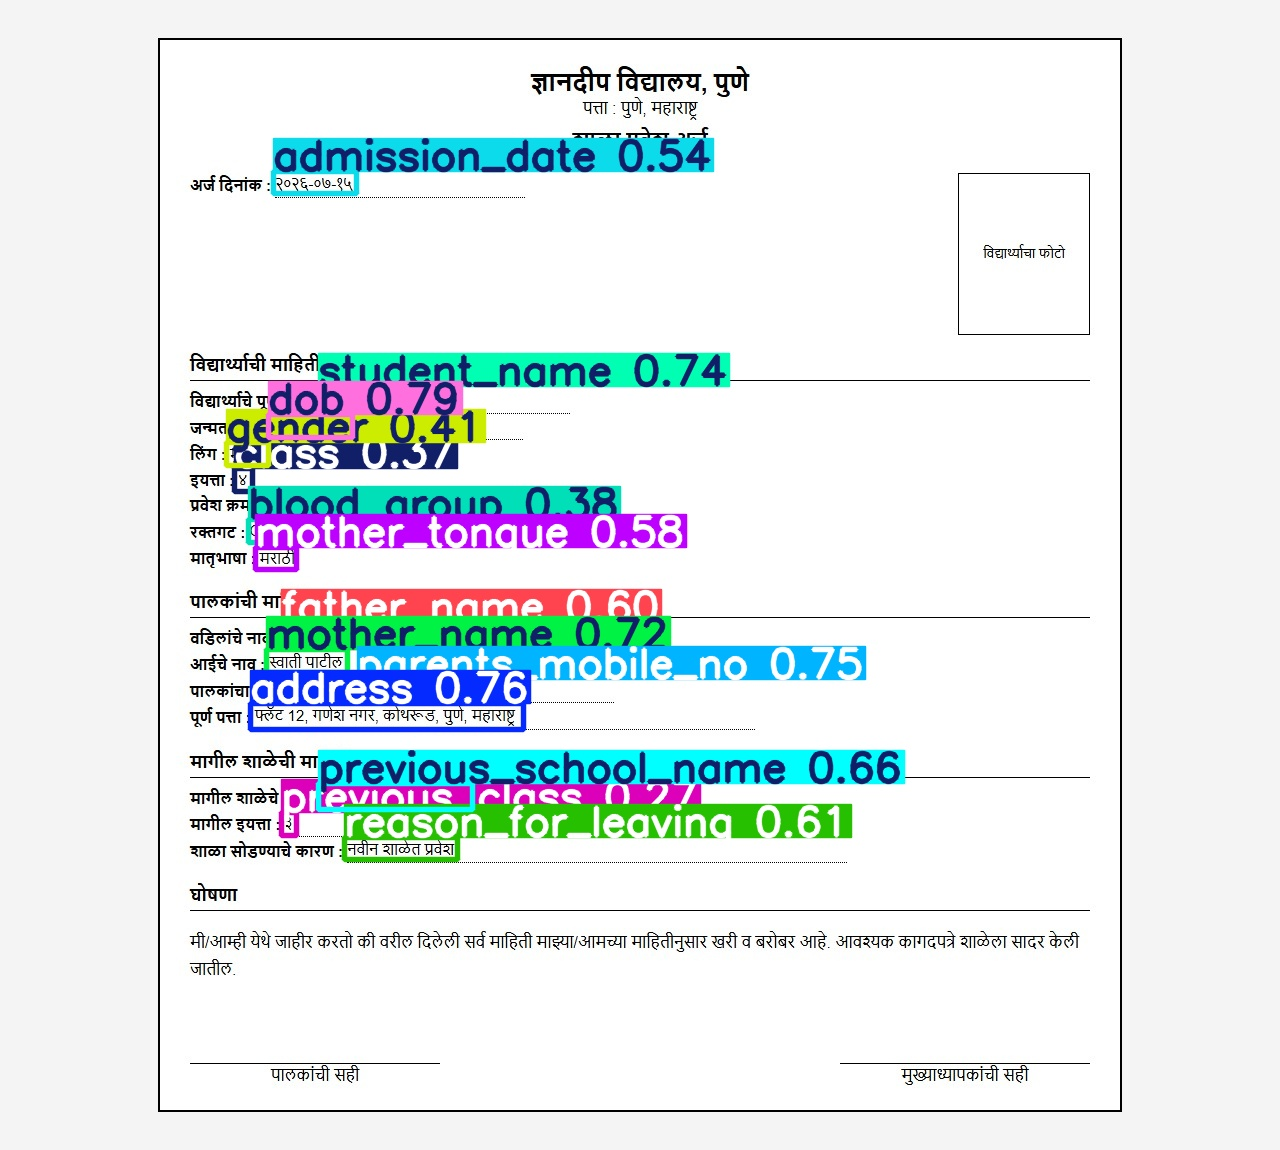

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display

# Load your trained model
model = YOLO(f'{HOME}/runs/detect/train2/weights/best.pt')

# Run detection on new image
results = model.predict(source='/content/admission_form_image1.jpeg', conf=0.25, save=True)

# Show result
save_path = os.path.join(str(results[0].save_dir), 'admission_form_image1.jpeg')
display(Image(filename=save_path, width=600))

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
import os

# Load your trained model
model = YOLO(f'{HOME}/runs/detect/train2/weights/best.pt')

# Run detection on new image
results = model.predict(source='/content/admission_form_image32.jpeg', conf=0.25, save=True)

# Show result
save_path = os.path.join(str(results[0].save_dir), 'admission_form_image32.jpeg')
display(Image(filename=save_path, width=600))

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
import os

# Load your trained model
model = YOLO(f'{HOME}/runs/detect/train2/weights/best.pt')

# Run detection on new image
results = model.predict(source='/content/admission_form_image1.jpeg', conf=0.1, save=True)

# Show result
save_path = os.path.join(str(results[0].save_dir), 'admission_form_image1.jpeg')
display(Image(filename=save_path, width=600))

In [ ]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 78.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.9 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.2.103 requires numpy<2.0.0,>=1.23.0, but you have numpy 2.5.1 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.1 which is incompatible.


In [ ]:
import easyocr
from ultralytics import YOLO
import cv2

# Load दोन्ही models
yolo_model = YOLO(f'{HOME}/runs/detect/train2/weights/best.pt')
reader = easyocr.Reader(['mr', 'en'])  # marathi + english

# Image वर detect करा
image_path = '/content/admission_form_image10.jpeg'
results = yolo_model.predict(source=image_path, conf=0.25)

img = cv2.imread(image_path)
extracted_data = {}

for box in results[0].boxes:
    cls_id = int(box.cls[0])
    field_name = yolo_model.names[cls_id]
    x1, y1, x2, y2 = map(int, box.xyxy[0])

    # त्या field चा crop काढा
    cropped = img[y1:y2, x1:x2]

    # OCR करा
    text_result = reader.readtext(cropped, detail=0)
    extracted_text = ' '.join(text_result)

    extracted_data[field_name] = extracted_text

print(extracted_data)

In [ ]:
import cv2
import re

# ============ फक्त हे बदला ============
image_path = '/content/admission_form_image89.jpeg'
# ========================================

# Setup (एकदाच करा, session मध्ये आधीच केलं असेल तर स्किप)
# import easyocr
# reader = easyocr.Reader(['mr', 'en'])

results = model.predict(source=image_path, conf=0.25)
img = cv2.imread(image_path)

extracted_data = {}
date_number_fields = ['dob', 'admission_date', 'class', 'previous_class']
admission_fields = ['admission_no']
blood_fields = ['blood_group']
pad = 5

for box in results[0].boxes:
    cls_id = int(box.cls[0])
    field_name = model.names[cls_id]
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    x1, y1 = max(0, x1-pad), max(0, y1-pad)
    x2, y2 = min(img.shape[1], x2+pad), min(img.shape[0], y2+pad)
    cropped = img[y1:y2, x1:x2]
    resized = cv2.resize(cropped, None, fx=8, fy=8, interpolation=cv2.INTER_CUBIC)

    if field_name in date_number_fields:
        raw = reader.readtext(resized, detail=1, allowlist='०१२३४५६७८९-',
                               decoder='beamsearch', beamWidth=10)
    elif field_name in admission_fields:
        raw = reader.readtext(resized, detail=1, allowlist='A०१२३४५६७८९-',
                               decoder='beamsearch', beamWidth=10)
    elif field_name in blood_fields:
        raw = reader.readtext(resized, detail=1, allowlist='ABO+-',
                               decoder='beamsearch', beamWidth=10)
    else:
        raw = reader.readtext(resized, detail=1, decoder='beamsearch', beamWidth=10)

    raw.sort(key=lambda r: r[0][0][0])
    text = ' '.join([r[1] for r in raw])
    extracted_data[field_name] = text if text else '❌ EMPTY'

# ---- Cleanup ----
def clean_text(text):
    text = re.sub(r'^[०.:ः\s]+', '', text)
    return text.strip()

def fix_date_format(date_str):
    parts = date_str.split('-')
    if len(parts) == 3:
        year, month, day = parts
        marathi_to_eng = str.maketrans('०१२३४५६७८९', '0123456789')
        if len(month.translate(marathi_to_eng)) == 1:
            month = '०' + month
        if len(day.translate(marathi_to_eng)) == 1:
            day = '०' + day
        return f"{year}-{month}-{day}"
    return date_str

for field in extracted_data:
    extracted_data[field] = clean_text(extracted_data[field])

extracted_data['admission_date'] = re.sub(r'-{2,}', '-', extracted_data['admission_date'])
extracted_data['dob'] = re.sub(r'-{2,}', '-', extracted_data['dob'])
extracted_data['admission_date'] = fix_date_format(extracted_data['admission_date'])
extracted_data['dob'] = fix_date_format(extracted_data['dob'])

# ---- Final Output ----
for field, value in extracted_data.items():
    print(f"{field}: {value}")


image 1/1 /content/admission_form_image89.jpeg: 736x800 1 address, 1 admission_date, 1 blood_group, 1 class, 1 dob, 1 father_name, 1 gender, 1 mother_name, 1 mother_tongue, 1 parents_mobile_no, 1 previous_class, 1 previous_school_name, 2 reason_for_leavings, 1 student_name, 22.1ms
Speed: 4.6ms preprocess, 22.1ms inference, 1.6ms postprocess per image at shape (1, 3, 736, 800)
parents_mobile_no: ७६६१५०७३७१
dob: २०१७-०९-०५
father_name: सचिन आनंदराव बिडवे
reason_for_leaving: "ी 770
address: सदनिका कर. ३५, खराडी, पुण ४११०४५
previous_school_name: छत्रपती शिवाजी विद्यालय 9 पुणे
student_name: अभिज्ञान सचिन बिडवे
mother_tongue: मराठी
mother_name: संगीता सचिन बिडवे
gender: मुलगा
admission_date: २०२७-०५-०१
blood_group: O+
previous_class: ७
class: ६


In [ ]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 23.2 MB/s eta 0:00:00


In [ ]:
from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH

def generate_lc(data, output_path='LC_certificate.docx'):
    doc = Document()

    # शाळेचं नाव - हेडर
    heading = doc.add_heading('ज्ञानदीप विद्यालय, पुणे', level=1)
    heading.alignment = WD_ALIGN_PARAGRAPH.CENTER

    sub = doc.add_paragraph('शाळा सोडल्याचा दाखला (Leaving Certificate)')
    sub.alignment = WD_ALIGN_PARAGRAPH.CENTER
    sub.runs[0].bold = True
    sub.runs[0].font.size = Pt(14)

    doc.add_paragraph('')  # spacing

    # विद्यार्थी माहिती
    fields_display = [
        ('विद्यार्थ्याचे पूर्ण नाव', 'student_name'),
        ('जन्मतारीख', 'dob'),
        ('लिंग', 'gender'),
        ('इयत्ता', 'class'),
        ('प्रवेश क्रमांक', 'admission_no'),
        ('प्रवेश दिनांक', 'admission_date'),
        ('रक्तगट', 'blood_group'),
        ('मातृभाषा', 'mother_tongue'),
        ('वडिलांचे नाव', 'father_name'),
        ('आईचे नाव', 'mother_name'),
        ('पालकांचा मोबाईल क्रमांक', 'parents_mobile_no'),
        ('पूर्ण पत्ता', 'address'),
        ('मागील शाळेचे नाव', 'previous_school_name'),
        ('मागील इयत्ता', 'previous_class'),
        ('शाळा सोडण्याचे कारण', 'reason_for_leaving'),
    ]

    table = doc.add_table(rows=0, cols=2)
    table.style = 'Table Grid'

    for label, key in fields_display:
        row = table.add_row()
        row.cells[0].text = label
        row.cells[1].text = data.get(key, '')
        row.cells[0].paragraphs[0].runs[0].bold = True

    doc.add_paragraph('')
    doc.add_paragraph('')

    # स्वाक्षऱ्या
    sign_para = doc.add_paragraph()
    sign_para.add_run('पालकांची सही' + ' '*50 + 'मुख्याध्यापकांची सही')

    doc.save(output_path)
    print(f"LC saved: {output_path}")


generate_lc(extracted_data)

LC saved: LC_certificate.docx
